# Drought Forecast Verification — Template Notebook

This notebook demonstrates the full `drought-forecast-eval` workflow:

1. **Download** (optional) fresh data from BGDI
2. **Load** forecast archive and observation archive
3. **Align** observations to the forecast grid
4. **Build** a reference forecast (climatology or persistence)
5. **Compute** verification scores
6. **Visualise** skill curves and regional maps
7. **Export** results (NetCDF, CSV, HTML report)

Copy this notebook and adapt the paths / settings for your specific experiment.

---
**Docs:** `docs/` | **Source:** `drought_forecast_eval/` | **Issues / MRs:** GitLab repo

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

# ── EDIT THESE PATHS ──────────────────────────────────────────────────────
ARCHIVE_DIR   = Path("../data/zipfiles")               # flat dir of daily ZIPs
HISTORIC_ZIP  = Path("../data/historic.csv.zip")      # full observation archive
SHAPEFILE     = Path('../shapefiles/BAFU_Grossregionen_v3.shp')
OUTPUT_DIR    = Path("./output")

DATE_RANGE    = ("2025-07-01", "2025-12-31")        # verification window
REGIONS       = "all"                                # or e.g. [1, 5, 12, 31]
VARIABLES     = "all"                                # or e.g. ["spi_1m", "cdi"]
CDI_THRESHOLD = 2                                    # CDI ≥ threshold = drought event
# ──────────────────────────────────────────────────────────────────────────

## 1. (Optional) Download fresh data from BGDI

In [3]:
from drought_forecast_eval.io.downloader import download_archive, download_historic

# Uncomment to download:
# download_archive(ARCHIVE_DIR, start=DATE_RANGE[0], end=DATE_RANGE[1])
download_historic(HISTORIC_ZIP)

PosixPath('../data/historic.csv.zip')

## 2. Load data

In [4]:
from drought_forecast_eval import load_forecasts, load_observations

region_ids = None if REGIONS == "all" else REGIONS

ds_fcst = load_forecasts(ARCHIVE_DIR, date_range=DATE_RANGE, region_ids=region_ids)
ds_obs  = load_observations(HISTORIC_ZIP, region_ids=region_ids)

trockenheitsdaten-numerisch_current.csv.202509192100.zip: filename date (2025-09-19) differs from header date (2025-09-18); using filename date.
trockenheitsdaten-numerisch_current.csv.202511042100.zip: filename date (2025-11-04) differs from header date (2025-11-03); using filename date.


In [5]:
ds_fcst

<xarray.Dataset> Size: 9MB
Dimensions:                  (forecast_reference_time: 181,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 1kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 220kB ...
Data variables: (12/39)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    ...                       ...
    spi_24m_p10              (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_24m_p50              (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_24m_p90              (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_ufc_p10    (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_ufc_p50    (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_ufc_p90    (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

In [6]:
ds_obs

<xarray.Dataset> Size: 10MB
Dimensions:              (drought_region_id: 38, valid_at: 1826)
Coordinates:
  * drought_region_id    (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * valid_at             (valid_at) datetime64[ns] 15kB 1990-12-31 ... 2025-1...
Data variables: (12/18)
    cdi                  (drought_region_id, valid_at) float64 555kB 1.0 ... 3.0
    precip_1m_index      (drought_region_id, valid_at) float64 555kB 1.0 ... 3.0
    precip_3m_index      (drought_region_id, valid_at) float64 555kB 1.0 ... 4.0
    precip_24m_index     (drought_region_id, valid_at) float64 555kB 1.0 ... 1.0
    hydro_index          (drought_region_id, valid_at) float64 555kB 1.0 ... 1.0
    soil_moisture_index  (drought_region_id, valid_at) float64 555kB nan ... 1.0
    ...                   ...
    spi_3m               (drought_region_id, valid_at) float64 555kB 0.77 ......
    spi_6m               (drought_region_id, valid_at) float64 555kB 0.4 ... ...
    spi_12m              (drought_region_id, valid_at) float64 555kB 0.82 ......
    spi_24m              (drought_region_id, valid_at) float64 555kB -0.47 .....
    soil_moisture_ufc    (drought_region_id, valid_at) float64 555kB nan ... ...
    vhi                  (drought_region_id, valid_at) float64 555kB nan ... ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought observation archive

## 3. Align observations to the forecast grid

In [7]:
from drought_forecast_eval import align_obs_to_forecast

ds_merged = align_obs_to_forecast(ds_fcst, ds_obs)
print("Merged dataset dims:", dict(ds_merged.dims))

Coverage for 'vhi_obs': 21149 / 27512 cells (76.9%)


Merged dataset dims: {'forecast_reference_time': 181, 'drought_region_id': 38, 'lead_week': 4}


/tmp/ipykernel_25762/3192283906.py:4: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("Merged dataset dims:", dict(ds_merged.dims))


In [8]:
ds_merged

<xarray.Dataset> Size: 13MB
Dimensions:                  (forecast_reference_time: 181,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 1kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 220kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

## 4. Build reference forecast

Choose `"climatology"`, `"persistence"`, or `"both

In [13]:
from drought_forecast_eval import climatology_reference, persistence_reference

# --- Climatology (week-of-year ± 4 weeks) ---
ds_ref_clim = climatology_reference(ds_obs, ds_fcst, week_window=4)

# --- Persistence (last observed value before each FRT) ---
ds_ref_pers = persistence_reference(ds_obs, ds_fcst)

print("Climatology reference variables:", list(ds_ref_clim.data_vars)[:5], "...")

Climatology reference variables: ['cdi_ref_p10', 'cdi_ref_p50', 'cdi_ref_p90', 'precip_1m_index_ref_p10', 'precip_1m_index_ref_p50'] ...


## 5 Explorative Data Analysis

In [14]:
import matplotlib.pylab as plt

In [15]:
RID = 31 # Region Identifier

In [16]:
%matplotlib inline
plt.show()

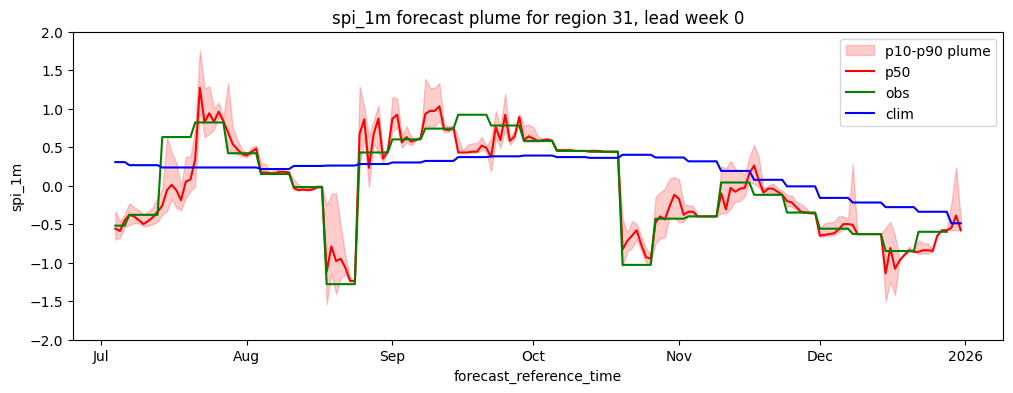

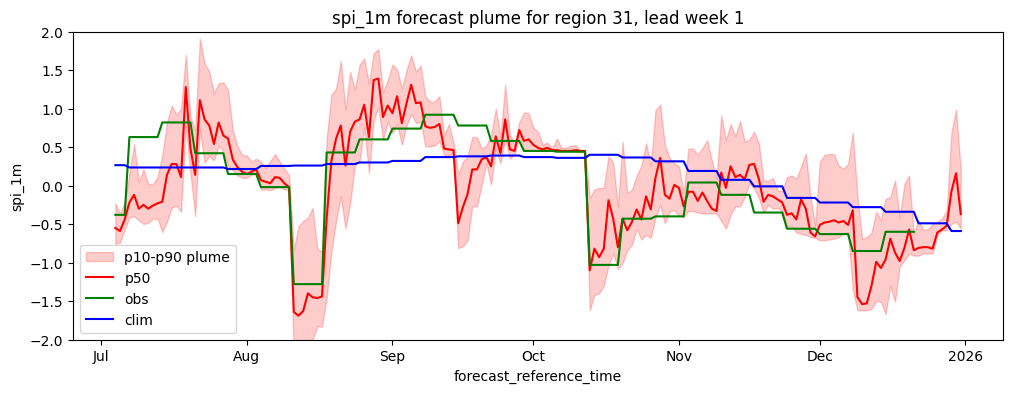

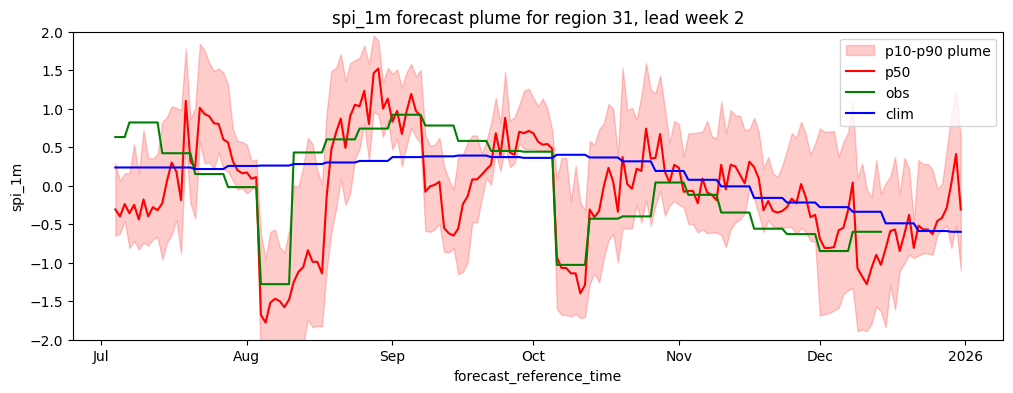

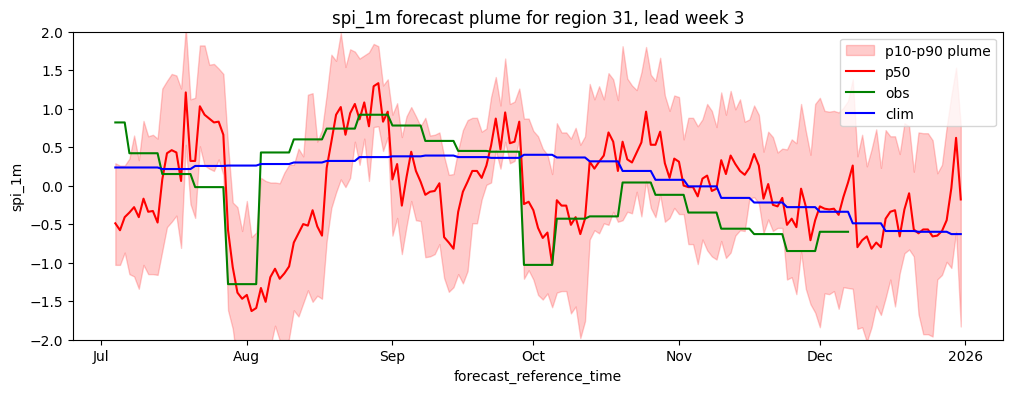

In [17]:
#ds_merged.isel(drought_region_id=0, lead_week=1)["spi_1m_obs"].plot()

VAR = "spi_1m"
for LW in range(4):
    f, ax = plt.subplots(figsize=(12, 4))
    
    series_p10 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p10"]
    series_p50 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p50"]
    series_p90 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p90"]
    series_obs = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_obs"]

    series_ref_clim = ds_ref_clim.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    series_ref_pers = ds_ref_pers.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    
    x = series_p50["forecast_reference_time"].values
    ax.fill_between(x, series_p10.values, series_p90.values, color="red", alpha=0.2, label="p10-p90 plume")
    series_p50.plot(x="forecast_reference_time", ax=ax, color="red", label="p50")
    series_obs.plot(x="forecast_reference_time", ax=ax, color="green", label="obs")
    series_ref_clim.plot(x="forecast_reference_time", ax=ax, color="blue", label="clim")
    #series_ref_pers.plot(x="forecast_reference_time", ax=ax, color="k", label="pers")
    
    ax.legend()
    ax.set_title(f"{VAR} forecast plume for region {RID}, lead week {LW}")
    ax.set_ylabel(VAR)
    ax.set_ylim([-2,2])
    plt.show()

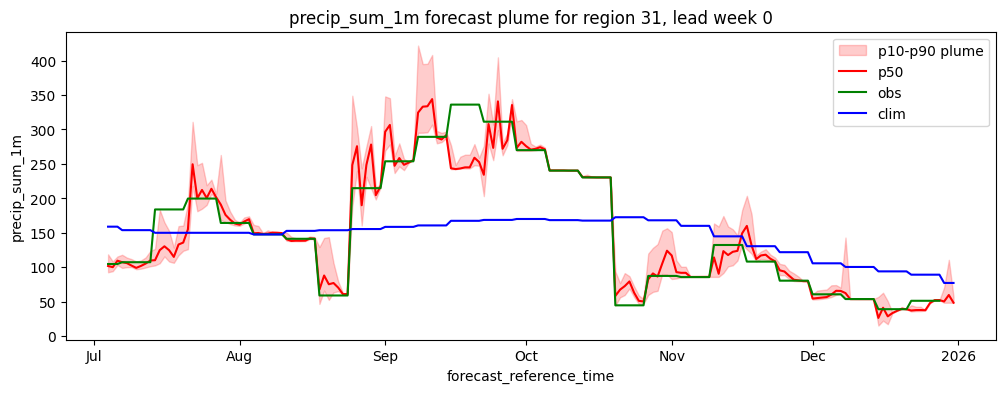

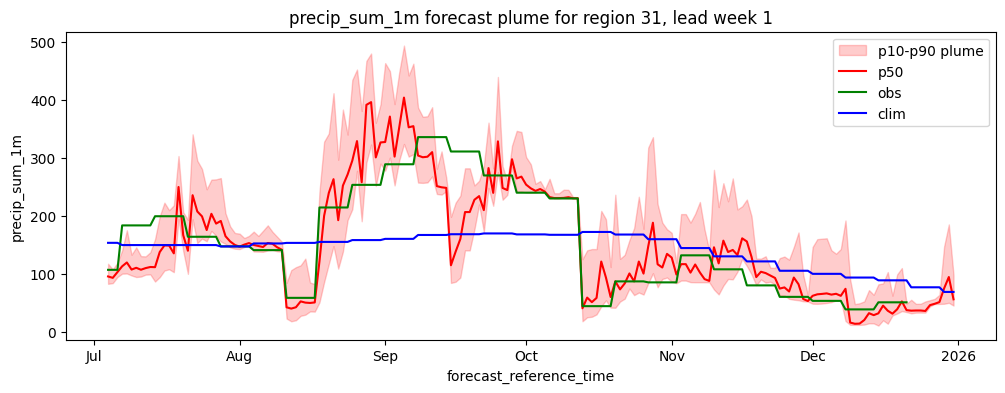

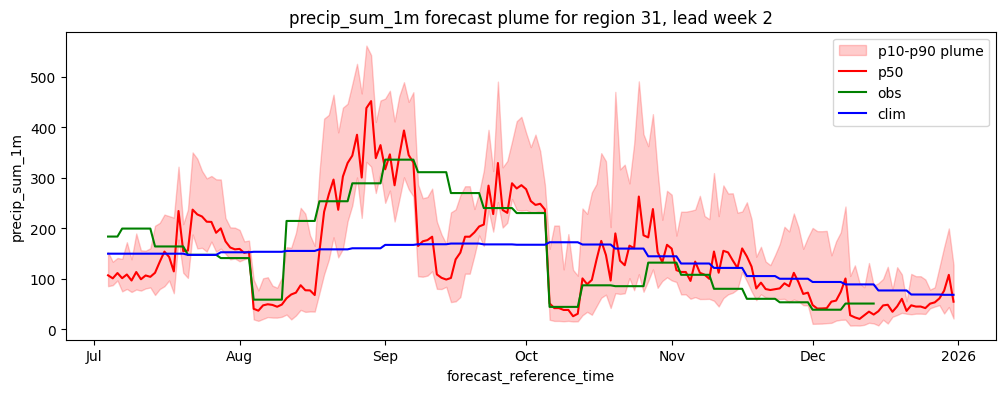

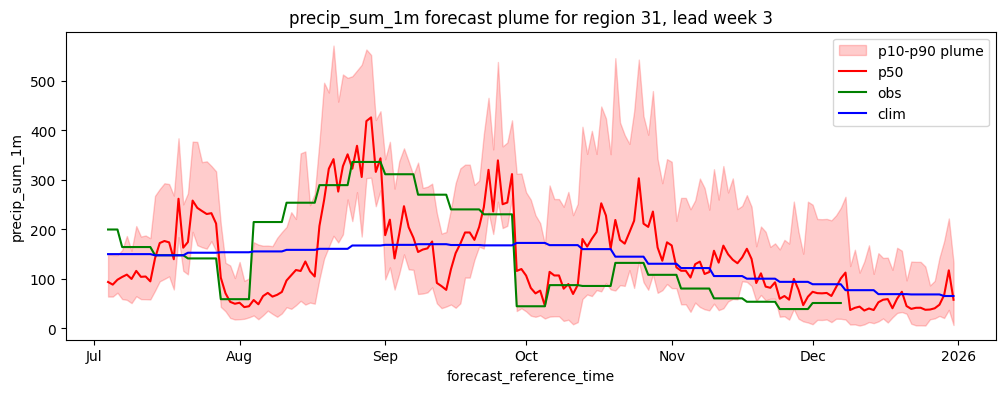

In [18]:
#ds_merged.isel(drought_region_id=0, lead_week=1)["spi_1m_obs"].plot()

VAR = "precip_sum_1m"
for LW in range(4):
    f, ax = plt.subplots(figsize=(12, 4))
    
    series_p10 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p10"]
    series_p50 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p50"]
    series_p90 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p90"]
    series_obs = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_obs"]

    series_ref_clim = ds_ref_clim.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    series_ref_pers = ds_ref_pers.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    
    x = series_p50["forecast_reference_time"].values
    ax.fill_between(x, series_p10.values, series_p90.values, color="red", alpha=0.2, label="p10-p90 plume")
    series_p50.plot(x="forecast_reference_time", ax=ax, color="red", label="p50")
    series_obs.plot(x="forecast_reference_time", ax=ax, color="green", label="obs")
    series_ref_clim.plot(x="forecast_reference_time", ax=ax, color="blue", label="clim")
    #series_ref_pers.plot(x="forecast_reference_time", ax=ax, color="k", label="pers")
    
    ax.legend()
    ax.set_title(f"{VAR} forecast plume for region {RID}, lead week {LW}")
    ax.set_ylabel(VAR)
    plt.show()

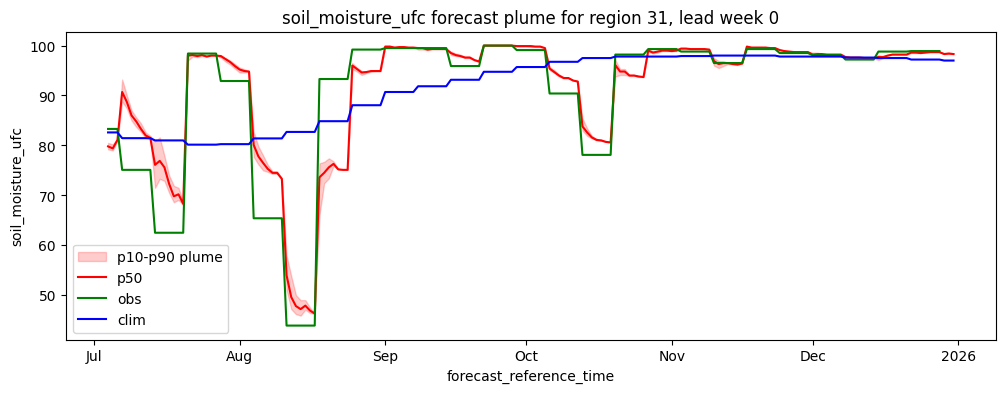

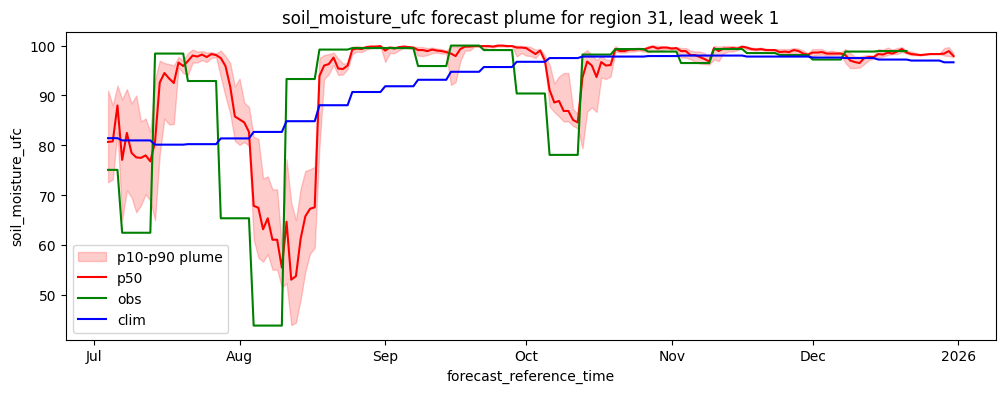

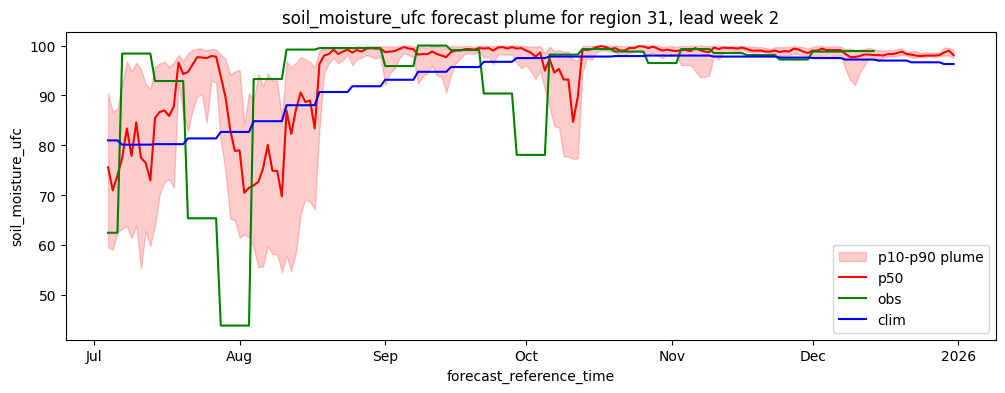

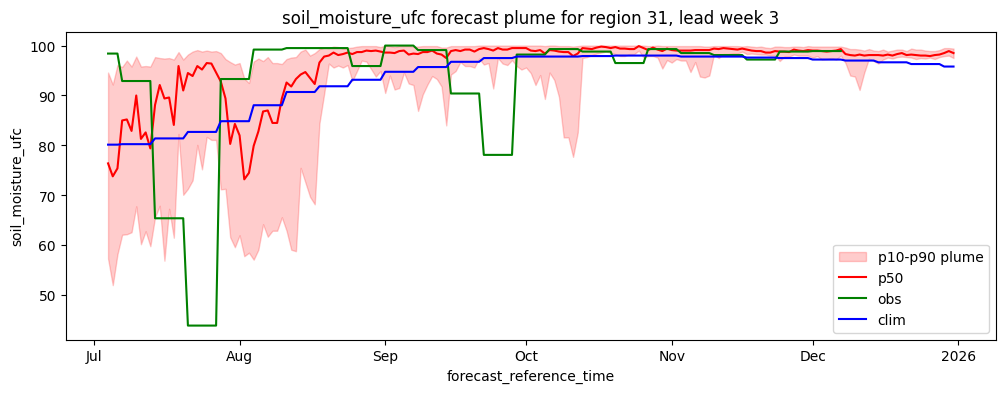

In [19]:
VAR = "soil_moisture_ufc"
for LW in range(4):
    f, ax = plt.subplots(figsize=(12, 4))
    
    series_p10 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p10"]
    series_p50 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p50"]
    series_p90 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p90"]
    series_obs = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_obs"]

    series_ref_clim = ds_ref_clim.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    series_ref_pers = ds_ref_pers.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    
    x = series_p50["forecast_reference_time"].values
    ax.fill_between(x, series_p10.values, series_p90.values, color="red", alpha=0.2, label="p10-p90 plume")
    series_p50.plot(x="forecast_reference_time", ax=ax, color="red", label="p50")
    series_obs.plot(x="forecast_reference_time", ax=ax, color="green", label="obs")
    series_ref_clim.plot(x="forecast_reference_time", ax=ax, color="blue", label="clim")
    #series_ref_pers.plot(x="forecast_reference_time", ax=ax, color="k", label="pers")
    
    ax.legend()
    ax.set_title(f"{VAR} forecast plume for region {RID}, lead week {LW}")
    ax.set_ylabel(VAR)
    plt.show()

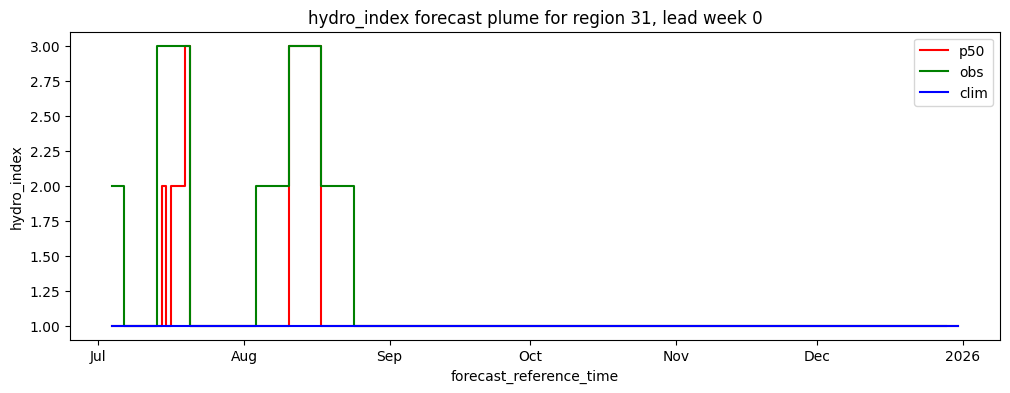

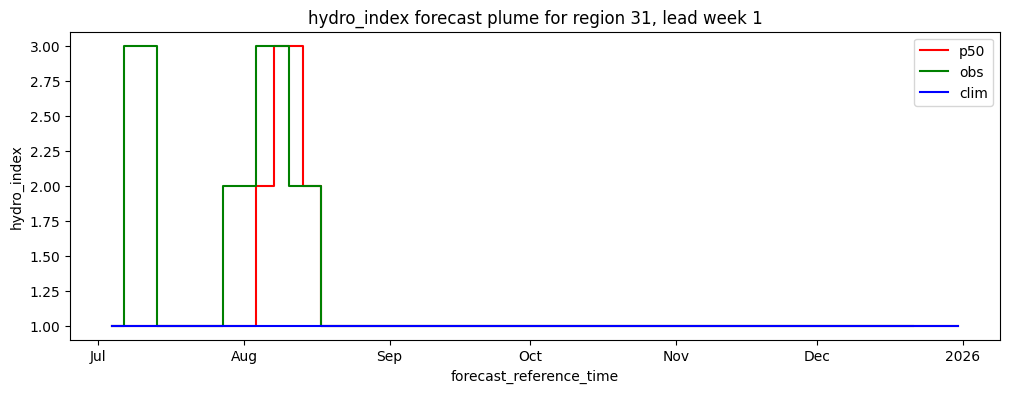

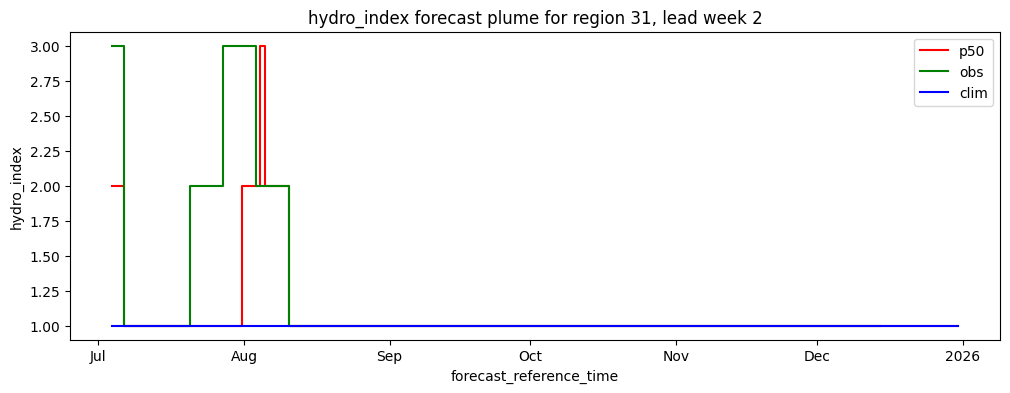

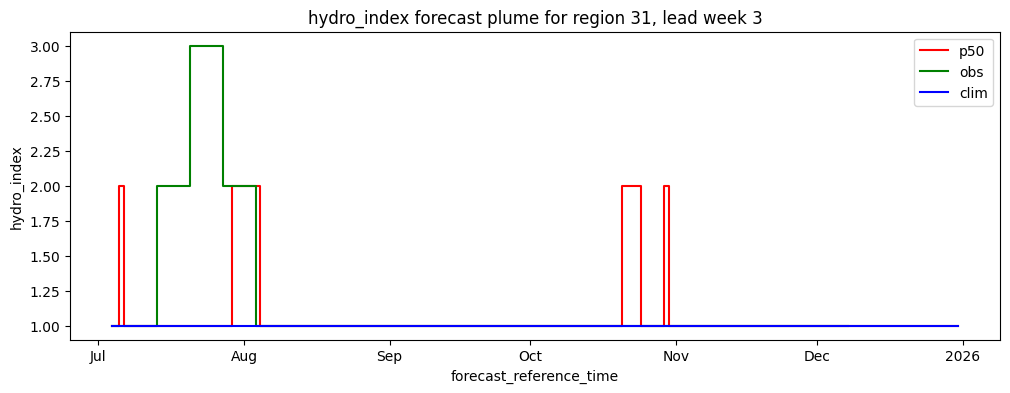

In [35]:
d_style = "steps-mid"
VAR = "hydro_index"

for LW in range(4):
    f, ax = plt.subplots(figsize=(12, 4))
    
    #series_p10 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p10"]
    series_p50 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p50"]
    #series_p90 = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_p90"]
    series_obs = ds_merged.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_obs"]

    series_ref_clim = ds_ref_clim.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    series_ref_pers = ds_ref_pers.isel(drought_region_id=RID, lead_week=LW)[f"{VAR}_ref_p50"]
    
    x = series_p50["forecast_reference_time"].values
    #ax.fill_between(x, series_p10.values, series_p90.values, color="red", alpha=0.2, label="p10-p90 plume")
    series_p50.plot(x="forecast_reference_time", ax=ax, color="red", label="p50", drawstyle=d_style)
    series_obs.plot(x="forecast_reference_time", ax=ax, color="green", label="obs", drawstyle=d_style)
    series_ref_clim.plot(x="forecast_reference_time", ax=ax, color="blue", label="clim", drawstyle=d_style)
    #series_ref_pers.plot(x="forecast_reference_time", ax=ax, color="k", label="pers")
    
    ax.legend()
    ax.set_title(f"{VAR} forecast plume for region {RID}, lead week {LW}")
    ax.set_ylabel(VAR)
    plt.show()

## 6. Compute scores

In [21]:
from drought_forecast_eval import compute_scores

ds_scores = compute_scores(
    ds_merged,
    variables=VARIABLES,
    scores="default",
    ds_ref=ds_ref_clim,
    cdi_threshold=CDI_THRESHOLD,
)

print("Score variables:", list(ds_scores.data_vars))
ds_scores

Score variables: ['cdi_mae', 'cdi_rmse', 'cdi_bias', 'cdi_correlation', 'precip_1m_index_mae', 'precip_1m_index_rmse', 'precip_1m_index_bias', 'precip_1m_index_correlation', 'precip_3m_index_mae', 'precip_3m_index_rmse', 'precip_3m_index_bias', 'precip_3m_index_correlation', 'precip_24m_index_mae', 'precip_24m_index_rmse', 'precip_24m_index_bias', 'precip_24m_index_correlation', 'hydro_index_mae', 'hydro_index_rmse', 'hydro_index_bias', 'hydro_index_correlation', 'soil_moisture_index_mae', 'soil_moisture_index_rmse', 'soil_moisture_index_bias', 'soil_moisture_index_correlation', 'precip_sum_1m_mae', 'precip_sum_1m_rmse', 'precip_sum_1m_bias', 'precip_sum_1m_correlation', 'precip_sum_1m_pinball', 'precip_sum_1m_interval_score', 'precip_sum_3m_mae', 'precip_sum_3m_rmse', 'precip_sum_3m_bias', 'precip_sum_3m_correlation', 'precip_sum_3m_pinball', 'precip_sum_3m_interval_score', 'precip_sum_6m_mae', 'precip_sum_6m_rmse', 'precip_sum_6m_bias', 'precip_sum_6m_correlation', 'precip_sum_6m_pin

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

In [22]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

### 5a. Add custom metrics
You can register your own scoring function and include it by name:

In [23]:
import xarray as xr
from drought_forecast_eval import register_score

def my_custom_score(fcst: xr.DataArray, obs: xr.DataArray, **kwargs) -> xr.DataArray:
    """Example: mean signed error."""
    return (fcst - obs).mean(dim=kwargs.get("reduce_dims", []))

register_score("signed_error", my_custom_score)

ds_scores_custom = compute_scores(
    ds_merged,
    variables=["spi_1m", "cdi"],
    scores=["mae", "signed_error"],
)
ds_scores_custom

<xarray.Dataset> Size: 3kB
Dimensions:            (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id  (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * lead_week          (lead_week) int64 32B 0 1 2 3
Data variables:
    spi_1m_mae         (drought_region_id, lead_week) float64 1kB 0.1211 ... ...
    cdi_mae            (drought_region_id, lead_week) float64 1kB 0.07865 ......
Attributes:
    source:            drought_forecast_eval
    variables_scored:  spi_1m,cdi
    scores_computed:   mae,signed_error
    cdi_threshold:     2.0
    reference_type:    none

## 6. Visualise results

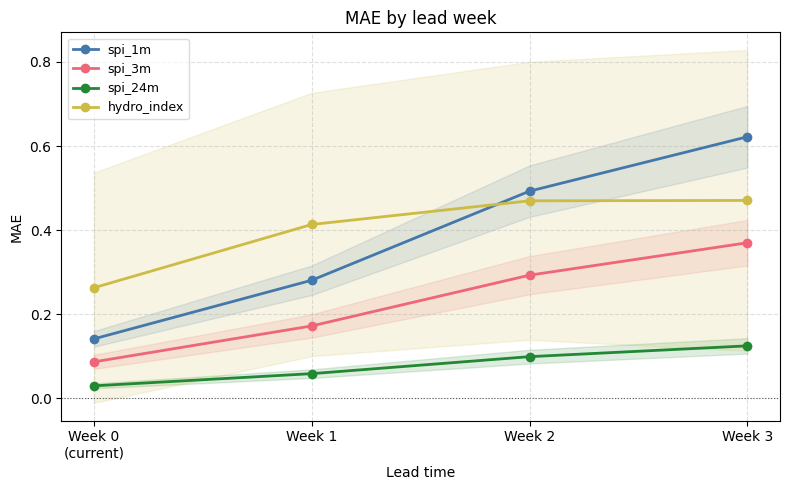

In [37]:
import matplotlib.pyplot as plt
from drought_forecast_eval.visualization import plot_skill_vs_lead

fig = plot_skill_vs_lead(
    ds_scores,
    variables=["spi_1m", "spi_3m", "spi_24m", "hydro_index"],
    score="mae",
    title="MAE by lead week",
)
plt.show()

In [42]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

In [47]:
help(plot_skill_vs_lead)

Help on function plot_skill_vs_lead in module drought_forecast_eval.visualization.skill_curves:

plot_skill_vs_lead(ds_scores: 'xr.Dataset', variables: 'list[str]', score: 'str' = 'mae', ds_scores_b: 'xr.Dataset | None' = None, label_a: 'str' = 'Forecast', label_b: 'str' = 'Reference', aggregate_regions: 'bool' = True, show_shading: 'bool' = True, zero_line: 'bool' = True, title: 'str | None' = None, ax: 'plt.Axes | None' = None, figsize: 'tuple[float, float]' = (8, 5)) -> 'plt.Figure'
    Plot score vs. lead week for multiple variables.

    Parameters
    ----------
    ds_scores:
        Scores dataset with dimensions ``(lead_week, drought_region_id)``.
    variables:
        List of variable keys (e.g. ``["spi_1m", "spi_6m"]``).
        The function looks for ``{variable}_{score}`` in the dataset.
    score:
        Metric name suffix (e.g. ``"mae"``, ``"rpss"``).
    ds_scores_b:
        Optional second scores dataset for experiment comparison.
    label_a, label_b:
        Legend

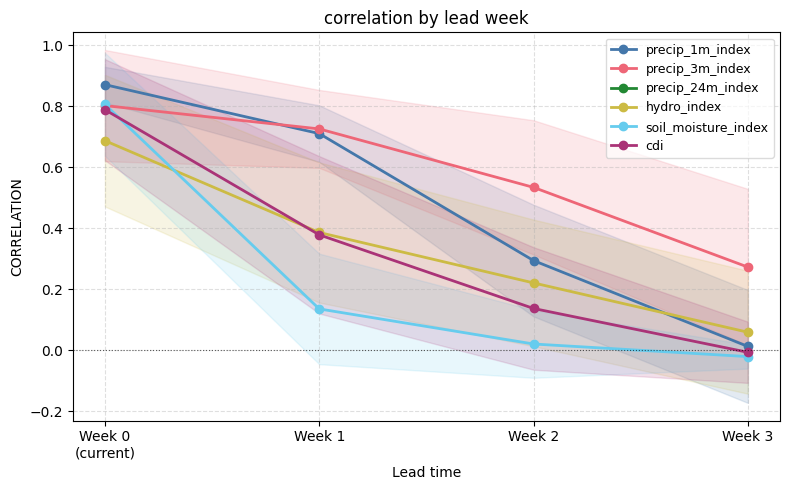

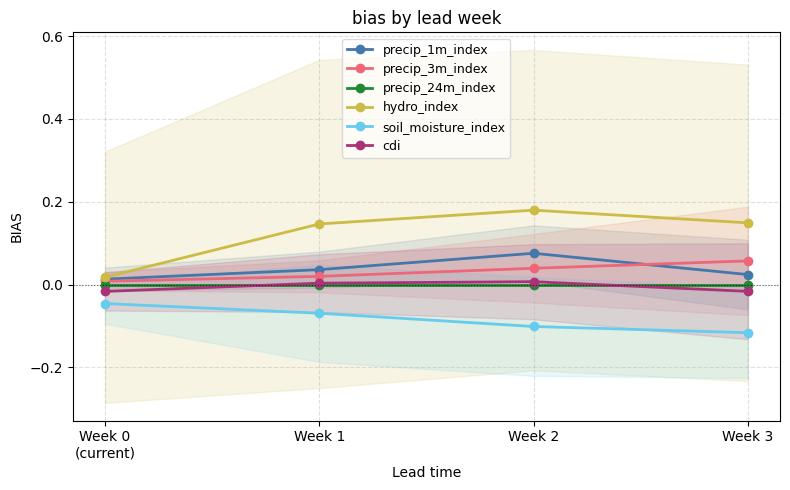

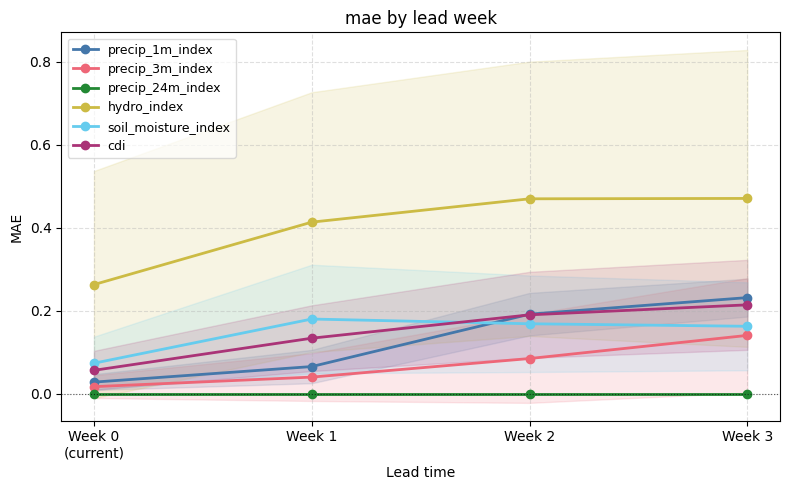

In [56]:
import matplotlib.pyplot as plt
from drought_forecast_eval.visualization import plot_skill_vs_lead



for _score in ["correlation","bias","mae"]:
    fig = plot_skill_vs_lead(
        ds_scores, #.sel(drought_region_id=31),
        variables=["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"],
        aggregate_regions=True,
        score=f"{_score}",
        title=f"{_score} by lead week",
    )
    plt.show()

In [62]:
ds_ref_clim["hydro_index_ref_p50"]

<xarray.DataArray 'hydro_index_ref_p50' (forecast_reference_time: 181,
                                         drought_region_id: 38, lead_week: 4)> Size: 220kB
array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
...
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]]], shape=(181, 38, 4))
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 1kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3

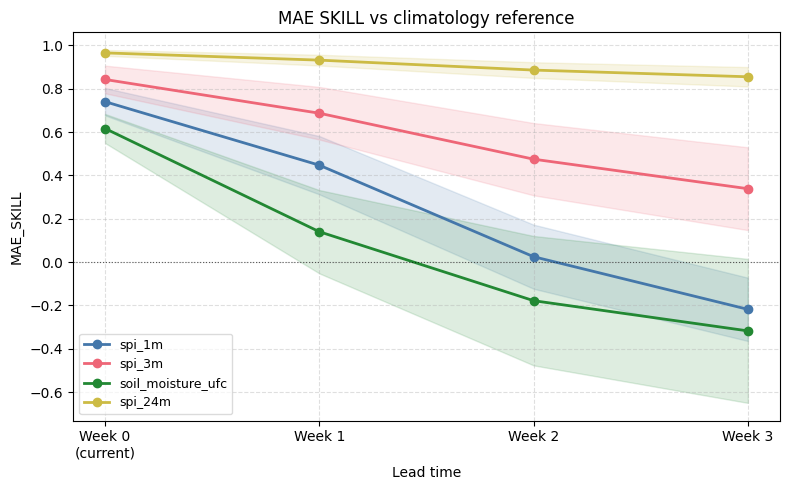

In [65]:
# RPSS (requires reference forecast)
ds_scores_w_skill = compute_scores(
    ds_merged,
    variables=["spi_1m", "spi_3m", "spi_24m", "soil_moisture_ufc", "hydro_index"],
    scores=["mae_skill"],
    ds_ref=ds_ref_clim,
)

fig2 = plot_skill_vs_lead(
    ds_scores_w_skill,
    variables=["spi_1m", "spi_3m","soil_moisture_ufc","spi_24m"],
    score="mae_skill",
    zero_line=True,
    title="MAE SKILL vs climatology reference",
)
plt.show()

In [144]:
ds_merged

<xarray.Dataset> Size: 13MB
Dimensions:                  (forecast_reference_time: 181,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 1kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 220kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 220kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

In [63]:
# Regional map (requires shapefile; falls back to bar chart if not provided)
from drought_forecast_eval.visualization import plot_region_map

fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="precip_1m_index_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="spi_3m_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="soil_moisture_ufc_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)


plt.show()

ValueError: 'precip_1m_index_skill' not found in ds_scores. Available: ['spi_1m_mae_skill', 'spi_3m_mae_skill', 'spi_24m_mae_skill', 'soil_moisture_ufc_mae_skill', 'hydro_index_mae_skill']

trockenheitsdaten-numerisch_current.csv.202509192100.zip: filename date (2025-09-19) differs from header date (2025-09-18); using filename date.
Coverage for 'vhi_obs': 6867 / 9272 cells (74.1%)


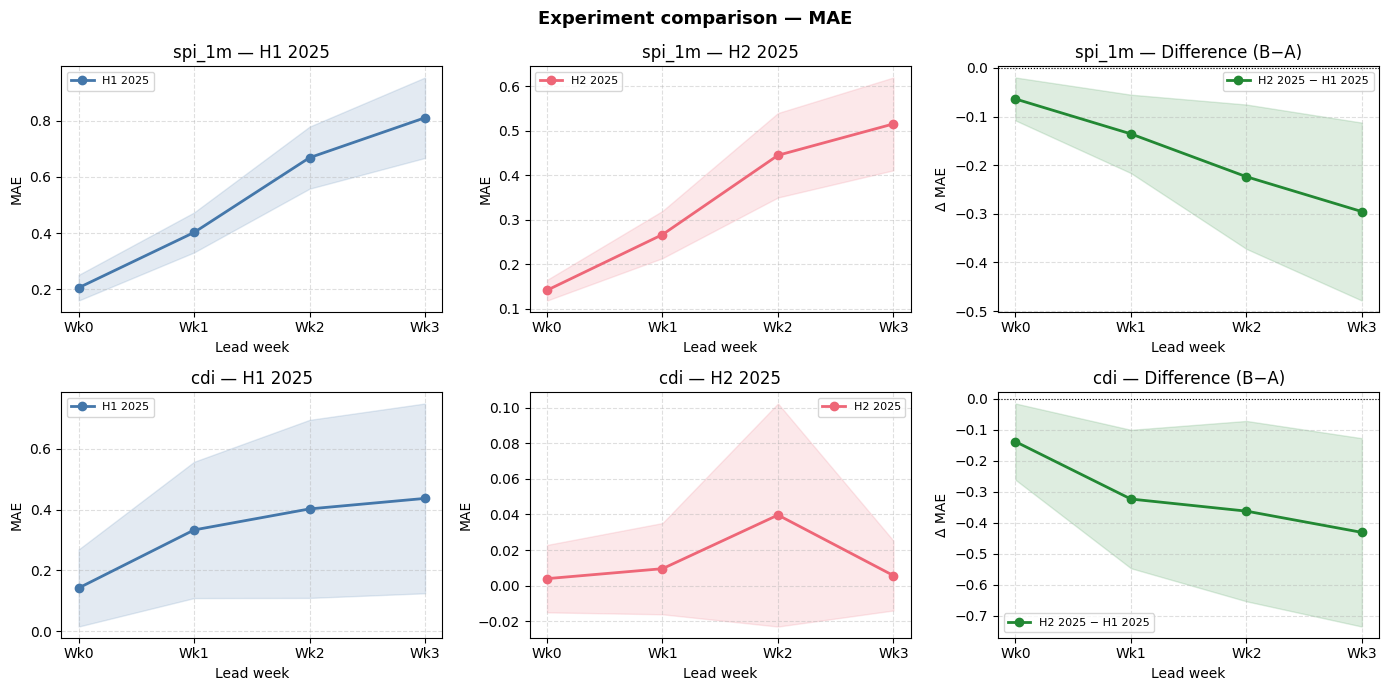

In [190]:
# Experiment comparison: period A vs period B
from drought_forecast_eval.visualization import plot_experiment_diff

# Example: compare first half vs second half of the year
DATE_RANGE_A = ("2025-07-01", "2025-08-29")
DATE_RANGE_B = ("2025-09-01", "2025-10-31")

ds_fcst_a = load_forecasts(ARCHIVE_DIR, date_range=DATE_RANGE_A, region_ids=region_ids)
ds_fcst_b = load_forecasts(ARCHIVE_DIR, date_range=DATE_RANGE_B, region_ids=region_ids)

ds_merged_a = align_obs_to_forecast(ds_fcst_a, ds_obs)
ds_merged_b = align_obs_to_forecast(ds_fcst_b, ds_obs)

ds_ref_a = climatology_reference(ds_obs, ds_fcst_a)
ds_ref_b = climatology_reference(ds_obs, ds_fcst_b)

ds_scores_a = compute_scores(ds_merged_a, variables=["spi_1m", "cdi"], scores=["mae"], ds_ref=ds_ref_a)
ds_scores_b = compute_scores(ds_merged_b, variables=["spi_1m", "cdi"], scores=["mae"], ds_ref=ds_ref_b)

fig4 = plot_experiment_diff(
    ds_scores_a, ds_scores_b,
    variables=["spi_1m", "cdi"],
    score="mae",
    label_a="H1 2025",
    label_b="H2 2025",
)
plt.show()

## 7. Export results

In [ ]:
from drought_forecast_eval import ReportBuilder

builder = ReportBuilder(
    archive_dir=ARCHIVE_DIR,
    historic_path=HISTORIC_ZIP,
    date_range=DATE_RANGE,
    regions=REGIONS,
    variables=VARIABLES,
    scores="default",
    reference="climatology",
    cdi_threshold=CDI_THRESHOLD,
    shapefile_path=SHAPEFILE,
    output_dir=OUTPUT_DIR,
)

# Run the full pipeline and write all outputs
outputs = builder.run()
print("Outputs:")
for key, path in outputs.items():
    print(f"  {key}: {path}")

In [ ]:
# Or export individually:
# builder.export_netcdf(OUTPUT_DIR / "scores.nc")
# builder.export_csv(OUTPUT_DIR / "scores_summary.csv")
# builder.export_html(OUTPUT_DIR / "report.html")